<a href="https://colab.research.google.com/github/atshaya179-coder/Amazon_prime/blob/main/Amazon_Prime_Video_EDA_Capstone_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Project Name**    -  **Amazon Prime Video Content Analysis**

##### **Project Type**    - EDA **Contribution**    - Individual





# **Problem Statement**

**BUSINESS PROBLEM OVERVIEW**

The streaming industry is highly competitive, and platforms such as Amazon Prime Video continuously expand their content libraries to serve diverse audiences. This project analyzes Amazon Prime Video titles available in the United States to understand content diversity, regional production, trends over time, ratings, popularity, and contributor patterns.

The dataset contains two CSV files: `titles.csv` with title-level information and `credits.csv` with actor/director information.

#### **Define Your Business Objective?**

***Understanding Content Strategy and Audience Preferences***

The objective is to use exploratory data analysis to identify patterns in Amazon Prime Video's content library that can support content acquisition, investment, regional strategy, audience targeting, and catalog planning.

# **General Guidelines** : -

1. Well-structured, formatted, and commented code is required.
2. Handle missing values and inconsistent data types appropriately.
3. Use Pandas and NumPy for data manipulation and computation.
4. Use Matplotlib and Seaborn for meaningful visualizations.
5. Explain the reason for selecting charts, the insights obtained, and the possible business impact.
6. Avoid drawing conclusions that are not supported by the dataset.

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [ ]:
# Import Libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import ast
import zipfile
import os

from google.colab import files

%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully.")


Libraries imported successfully.


### Dataset Loading

In [ ]:
# Upload the two ZIP files containing the datasets.
# Upload: titles.csv.zip and credits.csv.zip

uploaded = files.upload()

print("Uploaded files:")
for filename in uploaded.keys():
    print("-", filename)


Saving titles.csv.zip to titles.csv.zip
Saving credits.csv.zip to credits.csv.zip
Uploaded files:
- titles.csv.zip
- credits.csv.zip


In [ ]:
# Extract the ZIP files
for zip_name in ["titles.csv.zip", "credits.csv.zip"]:
    if os.path.exists(zip_name):
        with zipfile.ZipFile(zip_name, "r") as zip_ref:
            zip_ref.extractall("/content")

print("Dataset extraction completed.")
print("titles.csv exists:", os.path.exists("/content/titles.csv"))
print("credits.csv exists:", os.path.exists("/content/credits.csv"))


Dataset extraction completed.
titles.csv exists: True
credits.csv exists: True


In [ ]:
# Importing the datasets
titles = pd.read_csv("/content/titles.csv")
credits = pd.read_csv("/content/credits.csv")

print("Titles dataset shape:", titles.shape)
print("Credits dataset shape:", credits.shape)


Titles dataset shape: (9871, 15)
Credits dataset shape: (124235, 5)


### Dataset First View

In [ ]:
# Dataset First View
display(titles.head())
display(credits.head())


,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
0,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6
1,tm19248,The General,MOVIE,"During America’s Civil War, Union spies steal ...",1926,NaN,78,"['action', 'drama', 'war', 'western', 'comedy'...",['US'],NaN,tt0017925,8.2,89766.0,8.647,8.0
2,tm82253,The Best Years of Our Lives,MOVIE,It's the hope that sustains the spirit of ever...,1946,NaN,171,"['romance', 'war', 'drama']",['US'],NaN,tt0036868,8.1,63026.0,8.435,7.8
3,tm83884,His Girl Friday,MOVIE,"Hildy, the journalist former wife of newspaper...",1940,NaN,92,"['comedy', 'drama', 'romance']",['US'],NaN,tt0032599,7.8,57835.0,11.270,7.4
4,tm56584,In a Lonely Place,MOVIE,An aspiring actress begins to suspect that her...,1950,NaN,94,"['thriller', 'drama', 'romance']",['US'],NaN,tt0042593,7.9,30924.0,8.273,7.6


,person_id,id,name,character,role
0,59401,ts20945,Joe Besser,Joe,ACTOR
1,31460,ts20945,Moe Howard,Moe,ACTOR
2,31461,ts20945,Larry Fine,Larry,ACTOR
3,21174,tm19248,Buster Keaton,Johnny Gray,ACTOR
4,28713,tm19248,Marion Mack,Annabelle Lee,ACTOR


### Dataset Rows & Columns count

In [ ]:
# Dataset Rows & Columns
print("Titles rows and columns:", titles.shape)
print("Credits rows and columns:", credits.shape)


Titles rows and columns: (9871, 15)
Credits rows and columns: (124235, 5)


### Dataset Information

In [ ]:
# Dataset Information
print("Titles dataset information:")
titles.info()

print("\nCredits dataset information:")
credits.info()


Titles dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9871 entries, 0 to 9870
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    9871 non-null   object 
 1   title                 9871 non-null   object 
 2   type                  9871 non-null   object 
 3   description           9752 non-null   object 
 4   release_year          9871 non-null   int64  
 5   age_certification     3384 non-null   object 
 6   runtime               9871 non-null   int64  
 7   genres                9871 non-null   object 
 8   production_countries  9871 non-null   object 
 9   seasons               1357 non-null   float64
 10  imdb_id               9204 non-null   object 
 11  imdb_score            8850 non-null   float64
 12  imdb_votes            8840 non-null   float64
 13  tmdb_popularity       9324 non-null   float64
 14  tmdb_score            7789 non-null   float6

#### Duplicate Values

In [ ]:
# Dataset Duplicate Value Count
print("Duplicate rows in titles:", titles.duplicated().sum())
print("Duplicate rows in credits:", credits.duplicated().sum())
print("Duplicate title IDs:", titles["id"].duplicated().sum())


Duplicate rows in titles: 3
Duplicate rows in credits: 56
Duplicate title IDs: 3


#### Missing Values/Null Values

In [ ]:
# Missing Values/Null Values Count
print("Missing values in titles:")
display(titles.isnull().sum().sort_values(ascending=False).to_frame("Missing Values"))

print("Missing values in credits:")
display(credits.isnull().sum().sort_values(ascending=False).to_frame("Missing Values"))


Missing values in titles:


,Missing Values
seasons,8514
age_certification,6487
tmdb_score,2082
imdb_votes,1031
imdb_score,1021
imdb_id,667
tmdb_popularity,547
description,119
runtime,0
title,0


Missing values in credits:


,Missing Values
character,16287
person_id,0
id,0
name,0
role,0


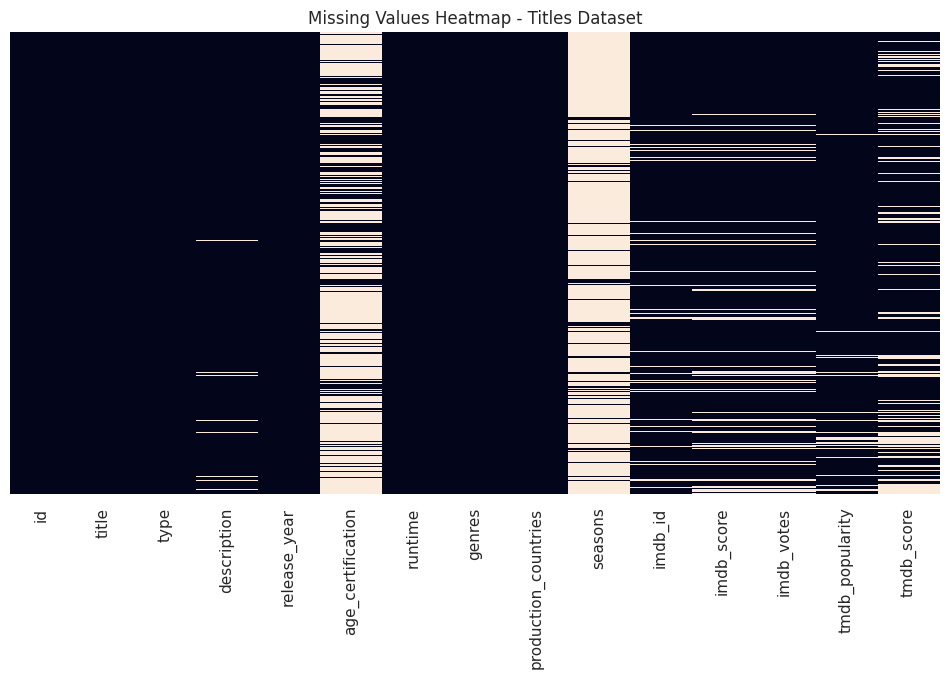

In [ ]:
# Visualizing missing values
plt.figure(figsize=(12, 6))
sns.heatmap(titles.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values Heatmap - Titles Dataset")
plt.show()


### What did you know about your dataset?

The titles dataset contains title-level information such as title name, content type, description, release year, certification, runtime, genres, production countries, seasons, IMDb metrics and TMDB metrics. The credits dataset contains people connected to titles, including actors and directors.

The two datasets can be connected through the common `id` field. This allows title-level analysis to be combined with contributor-level analysis.

## ***2. Understanding Your Variables***

In [ ]:
# Dataset Columns
print("Titles columns:")
print(titles.columns.tolist())

print("\nCredits columns:")
print(credits.columns.tolist())


Titles columns:
['id', 'title', 'type', 'description', 'release_year', 'age_certification', 'runtime', 'genres', 'production_countries', 'seasons', 'imdb_id', 'imdb_score', 'imdb_votes', 'tmdb_popularity', 'tmdb_score']

Credits columns:
['person_id', 'id', 'name', 'character', 'role']


In [ ]:
# Dataset Describe
display(titles.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,9871,9868,tm89134,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,9871,9737,The Lost World,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,9871,2,MOVIE,8514,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,9752,9734,No overview found.,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,9871.0,NaN,NaN,NaN,2001.327221,25.810071,1912.0,1995.5,2014.0,2018.0,2022.0
age_certification,3384,11,R,1249,NaN,NaN,NaN,NaN,NaN,NaN,NaN
runtime,9871.0,NaN,NaN,NaN,85.973052,33.512466,1.0,65.0,89.0,102.0,549.0
genres,9871,2028,['drama'],908,NaN,NaN,NaN,NaN,NaN,NaN,NaN
production_countries,9871,497,['US'],4810,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seasons,1357.0,NaN,NaN,NaN,2.791452,4.148958,1.0,1.0,1.0,3.0,51.0


### Variables Description

* **id:** Unique title ID on JustWatch.
* **title:** Name of the movie or TV show.
* **type:** Movie or TV show.
* **description:** Brief description of the title.
* **release_year:** Year in which the title was released.
* **age_certification:** Age/content certification.
* **runtime:** Runtime in minutes.
* **genres:** List of genres associated with the title.
* **production_countries:** Countries that produced the title.
* **seasons:** Number of seasons for TV shows.
* **imdb_id:** IMDb title identifier.
* **imdb_score:** IMDb rating.
* **imdb_votes:** Number of IMDb votes.
* **tmdb_popularity:** TMDB popularity score.
* **tmdb_score:** TMDB rating.

**Credits variables:**

* **person_id:** Person identifier.
* **id:** Title identifier.
* **name:** Actor or director name.
* **character:** Character name where applicable.
* **role:** ACTOR or DIRECTOR.

### Check Unique Values for each variable.

In [ ]:
# Check Unique Values for each variable
for column in titles.columns:
    print("No. of unique values in", column, "is", titles[column].nunique(), ".")


No. of unique values in id is 9868 .
No. of unique values in title is 9737 .
No. of unique values in type is 2 .
No. of unique values in description is 9734 .
No. of unique values in release_year is 110 .
No. of unique values in age_certification is 11 .
No. of unique values in runtime is 207 .
No. of unique values in genres is 2028 .
No. of unique values in production_countries is 497 .
No. of unique values in seasons is 32 .
No. of unique values in imdb_id is 9201 .
No. of unique values in imdb_score is 86 .
No. of unique values in imdb_votes is 3650 .
No. of unique values in tmdb_popularity is 5325 .
No. of unique values in tmdb_score is 89 .


In [ ]:
# Check unique values for selected categorical variables
for column in ["type", "age_certification"]:
    print("\n", column)
    print(titles[column].value_counts(dropna=False).head(20))



 type
type
MOVIE    8514
SHOW     1357
Name: count, dtype: int64

 age_certification
age_certification
NaN      6487
R        1249
PG-13     588
PG        582
G         269
TV-MA     217
TV-14     188
TV-PG      91
TV-Y       78
TV-G       57
TV-Y7      52
NC-17      13
Name: count, dtype: int64


## 3. ***Data Wrangling***

### Data Wrangling Code

In [ ]:
# Create a copy of the current datasets
df = titles.copy()
df_credits = credits.copy()

# Standardize column names in the credits dataset for easier analysis
df_credits = df_credits.rename(columns={"person_id": "person_ID", "character": "character_name"})

print("Titles copy shape:", df.shape)
print("Credits copy shape:", df_credits.shape)


Titles copy shape: (9871, 15)
Credits copy shape: (124235, 5)


In [ ]:
# Convert list-like columns into actual Python lists
for column in ["genres", "production_countries"]:
    df[column] = df[column].fillna("[]").apply(
        lambda x: ast.literal_eval(x) if isinstance(x, str) else x
    )

print("List-like columns converted successfully.")
display(df[["title", "genres", "production_countries"]].head())


List-like columns converted successfully.


,title,genres,production_countries
0,The Three Stooges,"[comedy, family, animation, action, fantasy, h...",[US]
1,The General,"[action, drama, war, western, comedy, european]",[US]
2,The Best Years of Our Lives,"[romance, war, drama]",[US]
3,His Girl Friday,"[comedy, drama, romance]",[US]
4,In a Lonely Place,"[thriller, drama, romance]",[US]


In [ ]:
# Convert numeric columns to numeric data types
numeric_columns = [
    "release_year", "runtime", "seasons",
    "imdb_score", "imdb_votes",
    "tmdb_popularity", "tmdb_score"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print(df[numeric_columns].dtypes)


release_year         int64
runtime              int64
seasons            float64
imdb_score         float64
imdb_votes         float64
tmdb_popularity    float64
tmdb_score         float64
dtype: object


In [ ]:

# Remove duplicate rows based on title ID
df = df.drop_duplicates(subset=["id"]).reset_index(drop=True)

# Verify duplicate title IDs after cleaning
print("Shape after removing duplicates:", df.shape)
print("Duplicate title IDs:", df["id"].duplicated().sum())


Shape after removing duplicates: (9868, 15)
Duplicate title IDs: 0


In [ ]:
# Create useful derived variables
df["content_age"] = 2026 - df["release_year"]

df["rating_category"] = pd.cut(
    df["imdb_score"],
    bins=[0, 5, 7, 8, 10],
    labels=["Low (0-5)", "Average (5-7)", "Good (7-8)", "Excellent (8-10)"],
    include_lowest=True
)

df["has_imdb_rating"] = df["imdb_score"].notna()

display(df[["title", "type", "release_year", "content_age", "imdb_score", "rating_category"]].head())


,title,type,release_year,content_age,imdb_score,rating_category
0,The Three Stooges,SHOW,1934,92,8.6,Excellent (8-10)
1,The General,MOVIE,1926,100,8.2,Excellent (8-10)
2,The Best Years of Our Lives,MOVIE,1946,80,8.1,Excellent (8-10)
3,His Girl Friday,MOVIE,1940,86,7.8,Good (7-8)
4,In a Lonely Place,MOVIE,1950,76,7.9,Good (7-8)


In [ ]:
# Content type counts
content_type_counts = df["type"].value_counts()
display(content_type_counts.to_frame("Title Count"))


,Title Count
type,
MOVIE,8511
SHOW,1357


In [ ]:
# Release year summary
release_year_summary = df.groupby("release_year").size().reset_index(name="title_count")
display(release_year_summary.head())
display(release_year_summary.tail())


,release_year,title_count
0,1912,1
1,1914,2
2,1915,5
3,1916,2
4,1917,1


,release_year,title_count
105,2018,685
106,2019,807
107,2020,698
108,2021,856
109,2022,89


In [ ]:
# Genre data preparation
genre_data = df[["id", "title", "type", "genres", "imdb_score"]].explode("genres")
genre_data = genre_data[genre_data["genres"].notna() & (genre_data["genres"] != "")]

genre_counts = (
    genre_data.groupby("genres")["id"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="title_count")
)

display(genre_counts.head(15))


,genres,title_count
0,drama,4762
1,comedy,2987
2,thriller,2119
3,action,1820
4,romance,1751
5,crime,1250
6,documentation,1096
7,horror,1065
8,family,751
9,european,712


In [ ]:
# Production country data preparation
country_data = df[["id", "title", "production_countries"]].explode("production_countries")
country_data = country_data[
    country_data["production_countries"].notna() &
    (country_data["production_countries"] != "")
]

country_counts = (
    country_data.groupby("production_countries")["id"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="title_count")
)

display(country_counts.head(15))


,production_countries,title_count
0,US,5331
1,IN,1072
2,GB,928
3,CA,530
4,FR,250
5,JP,197
6,AU,173
7,DE,172
8,IT,143
9,CN,143


In [ ]:
# IMDb rating analysis
imdb_summary = df["imdb_score"].describe()
display(imdb_summary.to_frame("IMDb Score"))


,IMDb Score
count,8847.000000
mean,5.976534
std,1.344028
min,1.100000
25%,5.100000
50%,6.100000
75%,6.900000
max,9.900000


In [ ]:
# IMDb votes analysis
votes_summary = df["imdb_votes"].describe()
display(votes_summary.to_frame("IMDb Votes"))


,IMDb Votes
count,8.837000e+03
mean,8.536485e+03
std,4.592768e+04
min,5.000000e+00
25%,1.180000e+02
50%,4.640000e+02
75%,2.237000e+03
max,1.133692e+06


In [ ]:
# TMDB popularity analysis
tmdb_summary = df["tmdb_popularity"].describe()
display(tmdb_summary.to_frame("TMDB Popularity"))


,TMDB Popularity
count,9321.000000
mean,6.912168
std,30.008727
min,0.000011
25%,1.234000
50%,2.537000
75%,5.640000
max,1437.906000


In [ ]:
# Movie and TV show rating comparison
rating_by_type = (
    df.groupby("type")["imdb_score"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)
display(rating_by_type)


,count,mean,median,min,max
type,,,,,
MOVIE,7681,5.80,5.9,1.1,9.9
SHOW,1166,7.12,7.3,1.3,9.7


In [ ]:
# Runtime analysis by content type
runtime_by_type = (
    df.groupby("type")["runtime"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)
display(runtime_by_type)


,count,mean,median,min,max
type,,,,,
MOVIE,8511,93.98,91.0,1,549
SHOW,1357,35.80,33.0,1,153


In [ ]:
# Age certification distribution
certification_counts = (
    df["age_certification"]
    .fillna("Not Rated")
    .value_counts()
    .reset_index()
)
certification_counts.columns = ["age_certification", "title_count"]
display(certification_counts)


,age_certification,title_count
0,Not Rated,6484
1,R,1249
2,PG-13,588
3,PG,582
4,G,269
5,TV-MA,217
6,TV-14,188
7,TV-PG,91
8,TV-Y,78
9,TV-G,57


In [ ]:
# Number of seasons analysis for TV shows
show_seasons = df[df["type"] == "SHOW"]["seasons"].dropna()

print("Number of TV shows with season information:", show_seasons.shape[0])
print("Average seasons:", round(show_seasons.mean(), 2))
print("Median seasons:", show_seasons.median())
print("Maximum seasons:", show_seasons.max())


Number of TV shows with season information: 1357
Average seasons: 2.79
Median seasons: 1.0
Maximum seasons: 51.0


In [ ]:
# Top-rated titles
top_rated = (
    df[df["imdb_score"].notna()]
    [["title", "type", "release_year", "imdb_score", "imdb_votes"]]
    .sort_values(["imdb_score", "imdb_votes"], ascending=[False, False])
    .head(20)
)

display(top_rated)


,title,type,release_year,imdb_score,imdb_votes
9132,Pawankhind,MOVIE,2022,9.9,2036.0
7780,Water Helps the Blood Run,SHOW,2019,9.7,30.0
9105,Couple of Mirrors,SHOW,2021,9.5,99.0
7419,The Chosen,SHOW,2019,9.4,25538.0
9420,Tari Sathe,MOVIE,2021,9.4,517.0
9049,Jai Bhim,MOVIE,2021,9.3,175187.0
9570,Pazhagiya Naatkal,MOVIE,2021,9.3,58.0
5110,Subaru Launch Control,SHOW,2013,9.3,30.0
7855,Soorarai Pottru,MOVIE,2020,9.2,109759.0
9324,Tom and Jerry,MOVIE,2021,9.2,357.0


In [ ]:
# Most-voted titles
most_voted = (
    df[df["imdb_votes"].notna()]
    [["title", "type", "release_year", "imdb_score", "imdb_votes"]]
    .sort_values("imdb_votes", ascending=False)
    .head(20)
)

display(most_voted)


,title,type,release_year,imdb_score,imdb_votes
2217,Titanic,MOVIE,1997,7.9,1133692.0
2227,The Usual Suspects,MOVIE,1995,8.5,1059480.0
2234,Braveheart,MOVIE,1995,8.4,1016629.0
2226,The Sixth Sense,MOVIE,1999,8.2,967864.0
1811,The Terminator,MOVIE,1984,8.1,841706.0
2807,Dexter,SHOW,2006,8.7,711566.0
4099,Skyfall,MOVIE,2012,7.8,684779.0
2821,District 9,MOVIE,2009,7.9,670344.0
5290,Arrival,MOVIE,2016,7.9,669220.0
2225,Fargo,MOVIE,1996,8.1,663221.0


In [ ]:
# Most popular titles according to TMDB popularity
most_popular = (
    df[df["tmdb_popularity"].notna()]
    [["title", "type", "release_year", "tmdb_popularity", "tmdb_score"]]
    .sort_values("tmdb_popularity", ascending=False)
    .head(20)
)

display(most_popular)


,title,type,release_year,tmdb_popularity,tmdb_score
8931,All the Old Knives,MOVIE,2022,1437.906,6.0
9037,Harina,SHOW,2022,951.863,5.5
9036,The eighth clause,MOVIE,2022,950.986,4.1
8961,Hotel Transylvania: Transformania,MOVIE,2022,934.545,7.1
7418,Sonic the Hedgehog,MOVIE,2020,893.650,7.4
8945,Clifford the Big Red Dog,MOVIE,2021,482.744,7.3
9089,Queen of Spades,MOVIE,2021,429.802,6.2
9008,Meander,MOVIE,2021,389.431,6.0
4096,Suits,SHOW,2011,356.533,8.1
5284,Better Call Saul,SHOW,2015,352.657,8.5


In [ ]:
# Role distribution in credits
role_counts = df_credits["role"].value_counts()
display(role_counts.to_frame("Credit Count"))


,Credit Count
role,
ACTOR,115846
DIRECTOR,8389


In [ ]:
# Top actors by number of unique titles
top_actors = (
    df_credits[df_credits["role"] == "ACTOR"]
    .groupby("name")["id"]
    .nunique()
    .sort_values(ascending=False)
    .head(20)
    .reset_index(name="title_count")
)

display(top_actors)


,name,title_count
0,George 'Gabby' Hayes,49
1,Roy Rogers,45
2,Bess Flowers,44
3,Gene Autry,40
4,Nassar,37
5,Herman Hack,35
6,Earl Dwire,34
7,George Morrell,34
8,Forrest Taylor,34
9,Charles King,34


In [ ]:
# Top directors by number of unique titles
top_directors = (
    df_credits[df_credits["role"] == "DIRECTOR"]
    .groupby("name")["id"]
    .nunique()
    .sort_values(ascending=False)
    .head(20)
    .reset_index(name="title_count")
)

display(top_directors)


,name,title_count
0,Joseph Kane,41
1,Sam Newfield,38
2,Jay Chapman,34
3,Lesley Selander,22
4,John English,21
5,Harry L. Fraser,21
6,William Nigh,20
7,Robert N. Bradbury,17
8,Manny Rodriguez,17
9,George Archainbaud,16


In [ ]:
# Merge title and credits data
merged_data = df_credits.merge(
    df[["id", "title", "type", "release_year", "imdb_score", "imdb_votes", "tmdb_popularity", "tmdb_score"]],
    on="id",
    how="left"
)

print("Merged data shape:", merged_data.shape)
display(merged_data.head())


Merged data shape: (124235, 12)


,person_ID,id,name,character_name,role,title,type,release_year,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
0,59401,ts20945,Joe Besser,Joe,ACTOR,The Three Stooges,SHOW,1934,8.6,1092.0,15.424,7.6
1,31460,ts20945,Moe Howard,Moe,ACTOR,The Three Stooges,SHOW,1934,8.6,1092.0,15.424,7.6
2,31461,ts20945,Larry Fine,Larry,ACTOR,The Three Stooges,SHOW,1934,8.6,1092.0,15.424,7.6
3,21174,tm19248,Buster Keaton,Johnny Gray,ACTOR,The General,MOVIE,1926,8.2,89766.0,8.647,8.0
4,28713,tm19248,Marion Mack,Annabelle Lee,ACTOR,The General,MOVIE,1926,8.2,89766.0,8.647,8.0


In [ ]:
# Analyze actors/directors connected to highly rated content
high_rated_people = (
    merged_data[merged_data["imdb_score"] >= 8]
    .groupby(["name", "role"])["id"]
    .nunique()
    .sort_values(ascending=False)
    .head(20)
    .reset_index(name="high_rated_title_count")
)

display(high_rated_people)


,name,role,high_rated_title_count
0,Prakash Raj,ACTOR,5
1,Mitzi Gaynor,ACTOR,5
2,Ajay Ghosh,ACTOR,4
3,Supergood Subramani,ACTOR,4
4,Tomokazu Seki,ACTOR,4
5,Tony Charmoli,DIRECTOR,4
6,Samantha Ruth Prabhu,ACTOR,4
7,Ruth Goodman,ACTOR,4
8,Peter Ginn,ACTOR,4
9,M. S. Bhaskar,ACTOR,4


In [ ]:
# Genre rating analysis
genre_rating = (
    genre_data.dropna(subset=["imdb_score"])
    .groupby("genres")
    .agg(
        average_imdb_score=("imdb_score", "mean"),
        title_count=("id", "nunique")
    )
    .query("title_count >= 20")
    .sort_values("average_imdb_score", ascending=False)
    .round(2)
)

display(genre_rating.head(15))


,average_imdb_score,title_count
genres,,
documentation,6.99,949
history,6.81,379
reality,6.75,129
animation,6.51,434
sport,6.44,224
war,6.40,316
european,6.31,698
music,6.20,395
family,6.15,724


In [ ]:
# Country rating analysis
country_rating = (
    country_data.dropna(subset=["id"])
    .merge(df[["id", "imdb_score"]], on="id", how="left")
    .dropna(subset=["imdb_score"])
    .groupby("production_countries")
    .agg(
        average_imdb_score=("imdb_score", "mean"),
        title_count=("id", "nunique")
    )
    .query("title_count >= 20")
    .sort_values("average_imdb_score", ascending=False)
    .round(2)
)

display(country_rating.head(15))


,average_imdb_score,title_count
production_countries,,
JP,6.66,172
CN,6.63,104
IL,6.56,31
AR,6.50,21
DK,6.44,23
CH,6.43,20
GB,6.42,847
KR,6.41,55
FR,6.39,241


### What all manipulations have you done and insights you found?

The data preparation included removing duplicate rows, converting numeric columns into appropriate numeric types, converting the genre and production-country columns from list-like strings into lists, and exploding those lists for category-level analysis.

Additional derived variables were created for content age and IMDb rating categories. The credits dataset was standardized and merged with the titles dataset using the common title ID.

These transformations make the dataset suitable for univariate, bivariate and multivariate exploratory analysis.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1 - Content Type Distribution (Univariate)

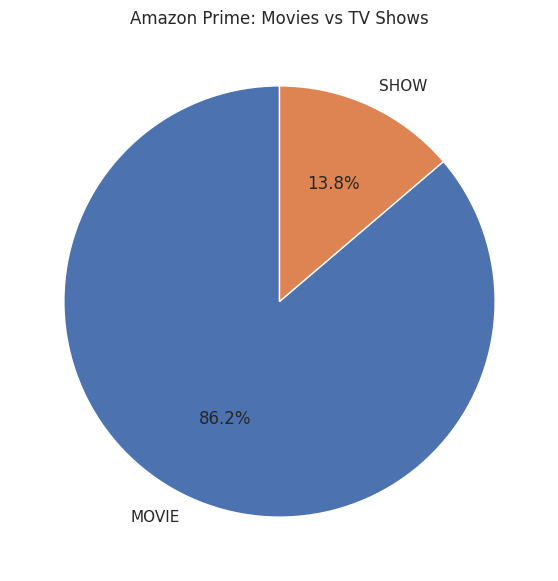

,Title Count
type,
MOVIE,8511
SHOW,1357


In [ ]:
# Chart - 1 visualization code
type_counts = df["type"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(type_counts.values, labels=type_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Amazon Prime: Movies vs TV Shows")
plt.show()

display(type_counts.to_frame("Title Count"))


##### 1. Why did you pick the specific chart?

A pie chart clearly shows the part-to-whole relationship between movies and TV shows. It is appropriate because the variable has two major categories.

##### 2. What is/are the insight(s) found from the chart?

The chart shows which content format represents the larger share of the Amazon Prime catalog in this dataset.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

Understanding the content mix can help Amazon balance investment between movies and TV shows. A strong imbalance may indicate an opportunity to strengthen an underrepresented format.

#### Chart - 2 - Content Released Over Time (Univariate)

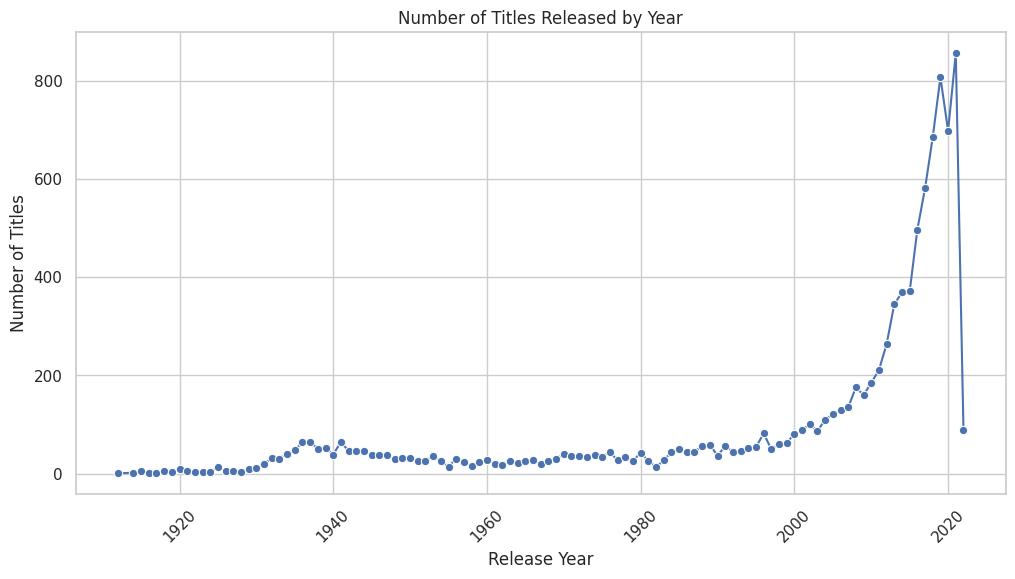

In [ ]:
# Chart - 2 visualization code
yearly_content = df.groupby("release_year").size().reset_index(name="title_count")

plt.figure(figsize=(12, 6))
sns.lineplot(data=yearly_content, x="release_year", y="title_count", marker="o")
plt.title("Number of Titles Released by Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.show()


##### 1. Why did you pick the specific chart?

A line chart is suitable for time-series trends because it makes increases, decreases and periods of rapid content growth easy to identify.

##### 2. What is/are the insight(s) found from the chart?

The trend shows how the number of titles in the dataset changes across release years. Recent periods can be compared with earlier periods to understand catalog growth.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

Understanding content growth helps with acquisition and production planning. A rapid increase may signal aggressive content expansion, while a decline may indicate a need for additional content investment.

#### Chart - 3 - Top Genres (Univariate)

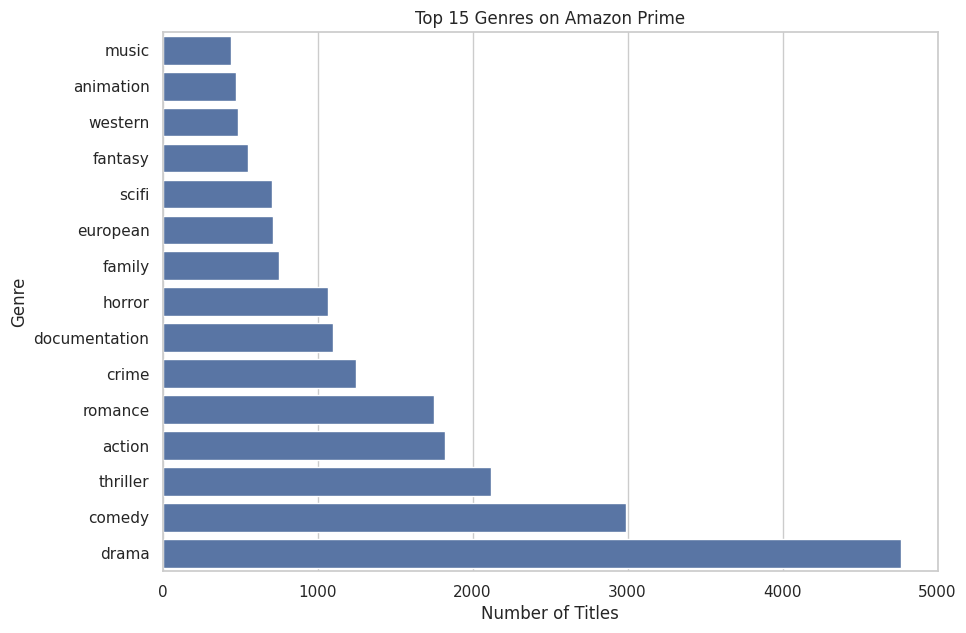

In [ ]:
# Chart - 3 visualization code
top_genres = genre_counts.head(15).sort_values("title_count")

plt.figure(figsize=(10, 7))
sns.barplot(data=top_genres, x="title_count", y="genres")
plt.title("Top 15 Genres on Amazon Prime")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.show()


##### 1. Why did you pick the specific chart?

A horizontal bar chart is effective for comparing many categorical groups because category names remain readable.

##### 2. What is/are the insight(s) found from the chart?

The chart identifies the genres with the largest representation in the catalog and highlights the concentration of content across genres.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

Genre concentration can guide content investment decisions. Amazon can maintain strong-performing categories while identifying opportunities to diversify into less represented genres.

#### Chart - 4 - Production Countries (Univariate)

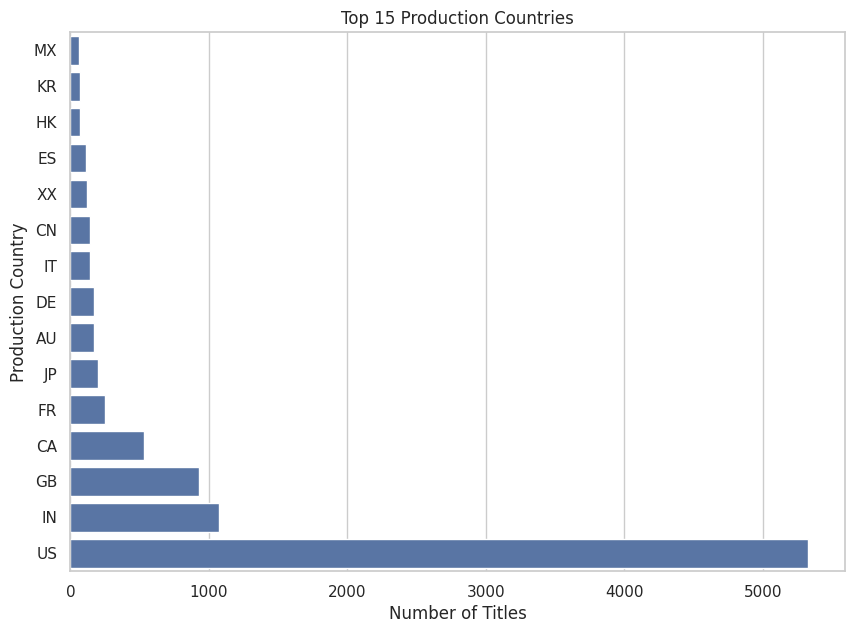

In [ ]:
# Chart - 4 visualization code
top_countries = country_counts.head(15).sort_values("title_count")

plt.figure(figsize=(10, 7))
sns.barplot(data=top_countries, x="title_count", y="production_countries")
plt.title("Top 15 Production Countries")
plt.xlabel("Number of Titles")
plt.ylabel("Production Country")
plt.show()


##### 1. Why did you pick the specific chart?

A bar chart allows direct comparison of the number of titles associated with each production country.

##### 2. What is/are the insight(s) found from the chart?

The chart shows which countries contribute most strongly to the catalog and therefore provides an indication of geographic content diversity.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

Regional production information can support international content acquisition and localization strategies. Strong representation in a region can be balanced with investments in underrepresented markets.

#### Chart - 5 - IMDb Score Distribution (Univariate)

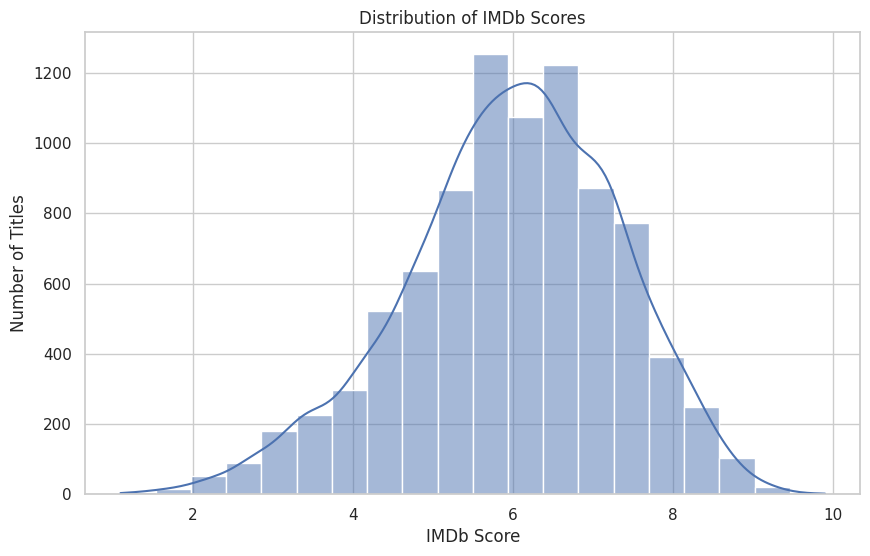

In [ ]:
# Chart - 5 visualization code
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x="imdb_score", bins=20, kde=True)
plt.title("Distribution of IMDb Scores")
plt.xlabel("IMDb Score")
plt.ylabel("Number of Titles")
plt.show()


##### 1. Why did you pick the specific chart?

A histogram is appropriate for understanding the distribution of a continuous numerical variable such as IMDb score.

##### 2. What is/are the insight(s) found from the chart?

The distribution indicates where most titles fall in terms of IMDb ratings and whether ratings are concentrated around particular score ranges.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

Rating distribution provides a high-level view of catalog quality. Amazon can use such information together with popularity and engagement measures when evaluating content strategy.

#### Chart - 6 - IMDb Score by Content Type (Bivariate)

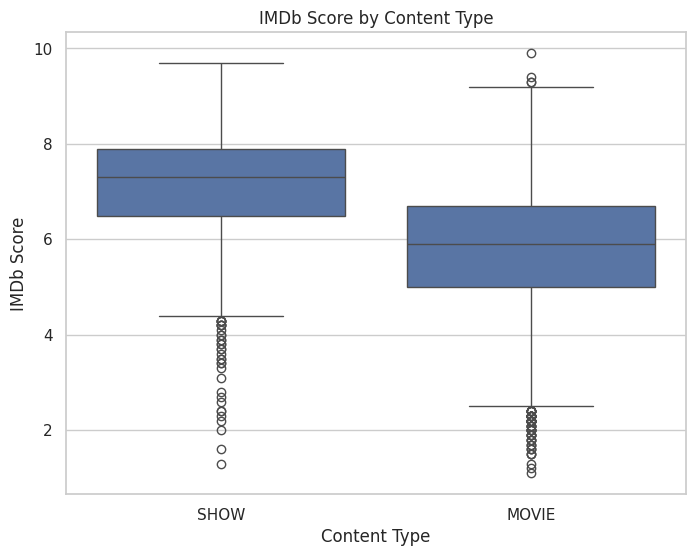

In [ ]:
# Chart - 6 visualization code
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x="type", y="imdb_score")
plt.title("IMDb Score by Content Type")
plt.xlabel("Content Type")
plt.ylabel("IMDb Score")
plt.show()


##### 1. Why did you pick the specific chart?

A box plot compares the distribution, median and spread of IMDb scores across movies and TV shows and also makes potential outliers visible.

##### 2. What is/are the insight(s) found from the chart?

The chart allows comparison of the typical IMDb rating and rating variability between the two content formats.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

This comparison can support format-level quality analysis. If one format consistently receives stronger ratings, investment and quality-control strategies can be adjusted accordingly.

#### Chart - 7 - Runtime and IMDb Score (Bivariate)

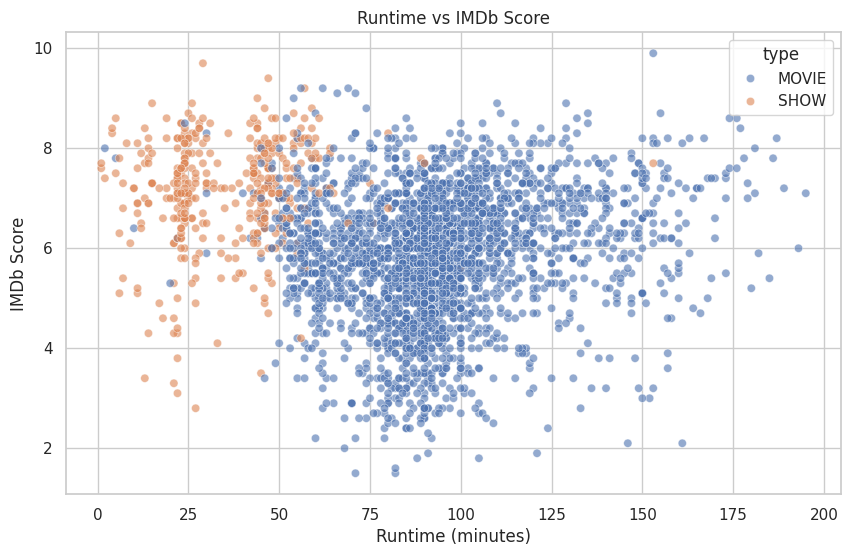

In [ ]:
# Chart - 7 visualization code
runtime_rating = df[["runtime", "imdb_score", "type"]].dropna()

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=runtime_rating.sample(min(3000, len(runtime_rating)), random_state=42),
    x="runtime",
    y="imdb_score",
    hue="type",
    alpha=0.6
)
plt.title("Runtime vs IMDb Score")
plt.xlabel("Runtime (minutes)")
plt.ylabel("IMDb Score")
plt.show()


##### 1. Why did you pick the specific chart?

A scatter plot is useful for investigating whether two numerical variables have a visible relationship.

##### 2. What is/are the insight(s) found from the chart?

The chart shows whether titles with longer or shorter runtimes appear to have systematically different IMDb scores. The relationship should be interpreted as association rather than causation.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

Runtime insights can inform programming and audience strategy, but runtime alone should not be used to determine content quality.

#### Chart - 8 - IMDb Votes vs IMDb Score (Bivariate)

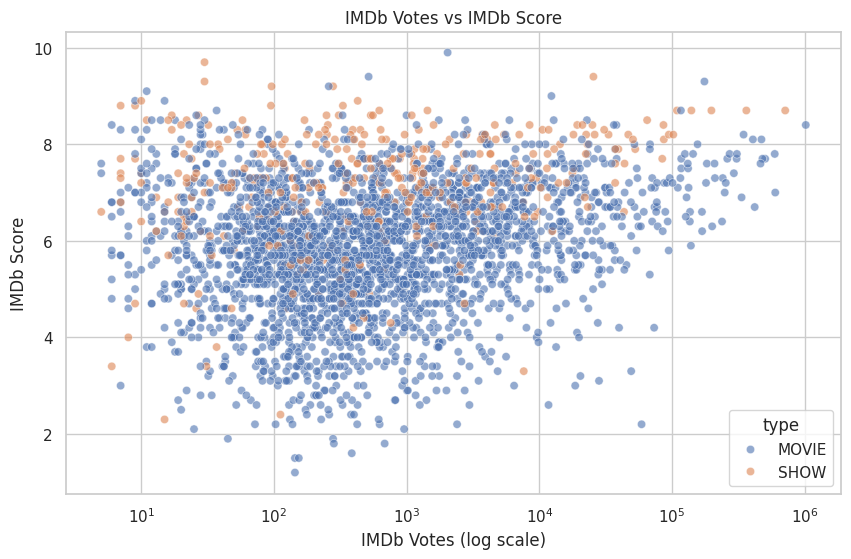

In [ ]:
# Chart - 8 visualization code
votes_rating = df[["imdb_votes", "imdb_score", "type"]].dropna()
sample_votes = votes_rating.sample(min(3000, len(votes_rating)), random_state=42)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=sample_votes,
    x="imdb_votes",
    y="imdb_score",
    hue="type",
    alpha=0.6
)
plt.xscale("log")
plt.title("IMDb Votes vs IMDb Score")
plt.xlabel("IMDb Votes (log scale)")
plt.ylabel("IMDb Score")
plt.show()


##### 1. Why did you pick the specific chart?

A scatter plot shows the relationship between audience voting volume and rating. A logarithmic x-axis is used because vote counts can vary substantially.

##### 2. What is/are the insight(s) found from the chart?

The chart helps distinguish widely voted titles from titles with relatively few votes and shows whether vote volume is associated with rating.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

Highly voted content can be a useful indicator of visibility and audience engagement. It can complement rating-based decisions when identifying important catalog titles.

#### Chart - 9 - Numeric Variables Distribution (Univariate)

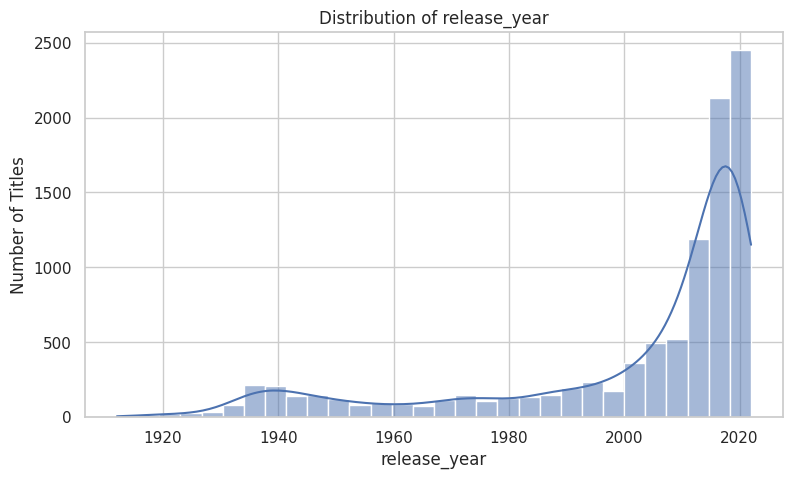

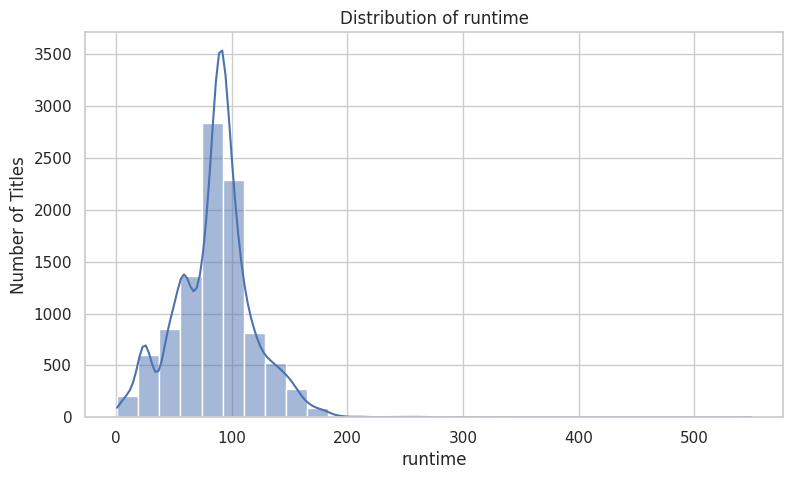

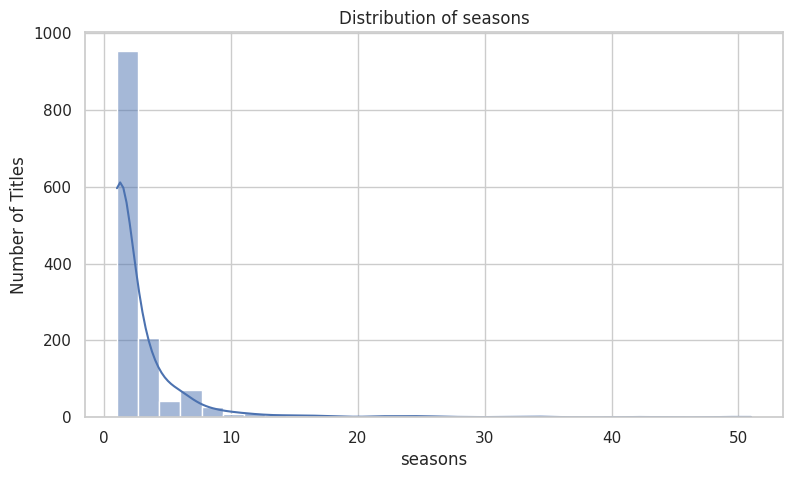

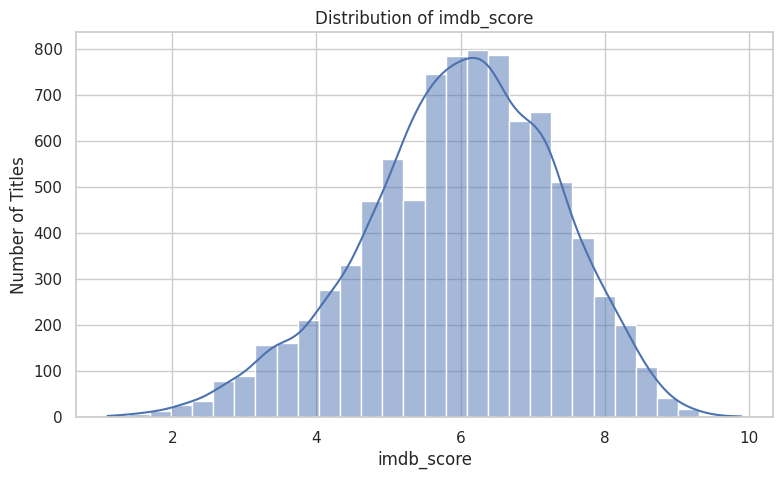

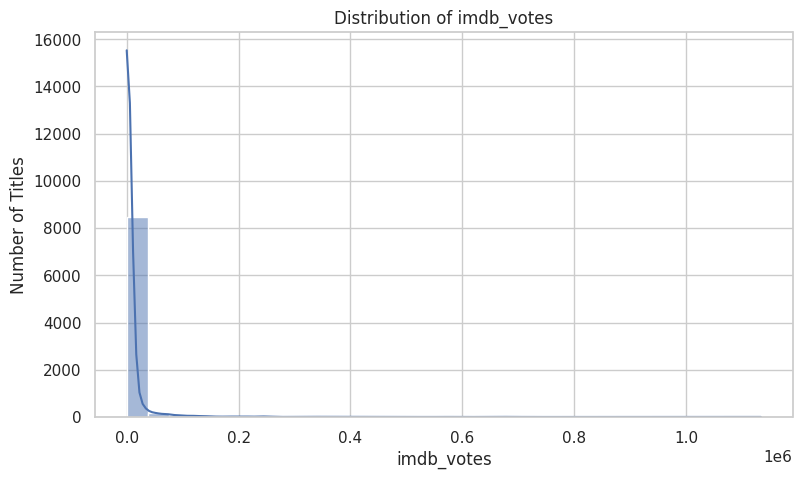

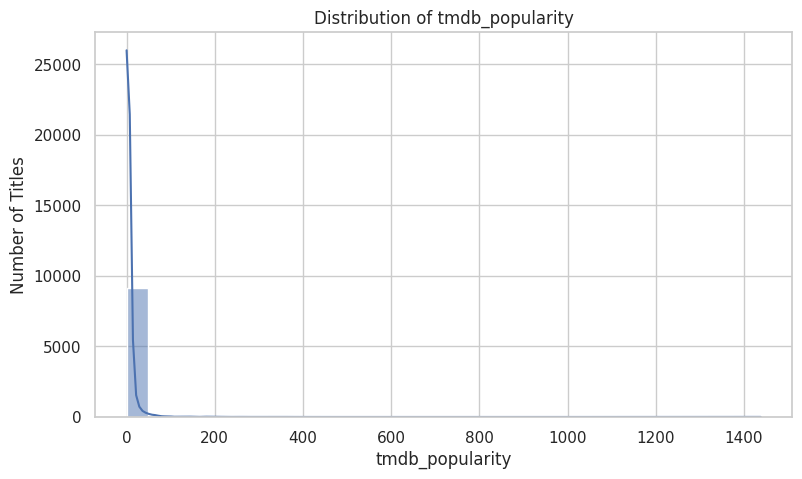

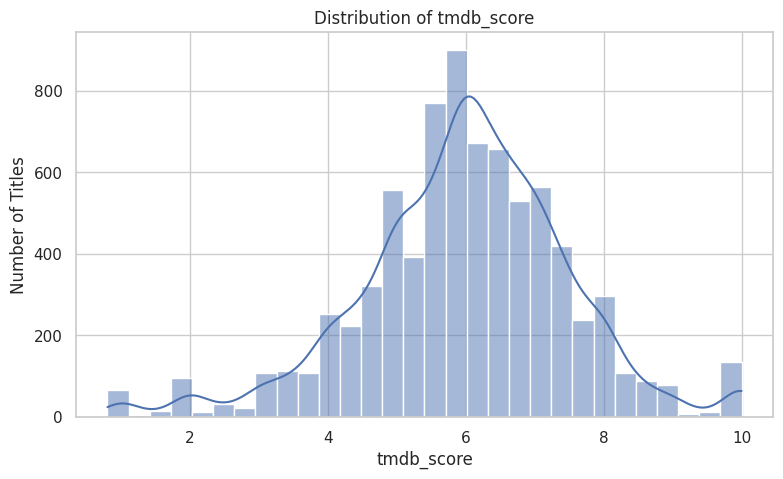

In [ ]:
# Chart - 9 visualization code
numeric_plot_columns = [
    "release_year", "runtime", "seasons",
    "imdb_score", "imdb_votes",
    "tmdb_popularity", "tmdb_score"
]

for column in numeric_plot_columns:
    plt.figure(figsize=(9, 5))
    sns.histplot(df[column].dropna(), kde=True, bins=30)
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Number of Titles")
    plt.show()


##### 1. Why did you pick the specific chart?

Histograms are useful for understanding the shape, spread and potential skewness of numerical variables.

##### 2. What is/are the insight(s) found from the chart?

The distributions show how release years, runtime, seasons, ratings, votes and popularity vary across the catalog. IMDb votes and TMDB popularity may be especially skewed because a small number of titles can be highly visible.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

Distribution analysis helps identify unusual values and prevents misleading summaries. It is useful before building further statistical analyses or predictive models.

#### Chart - 10 - Correlation Heatmap

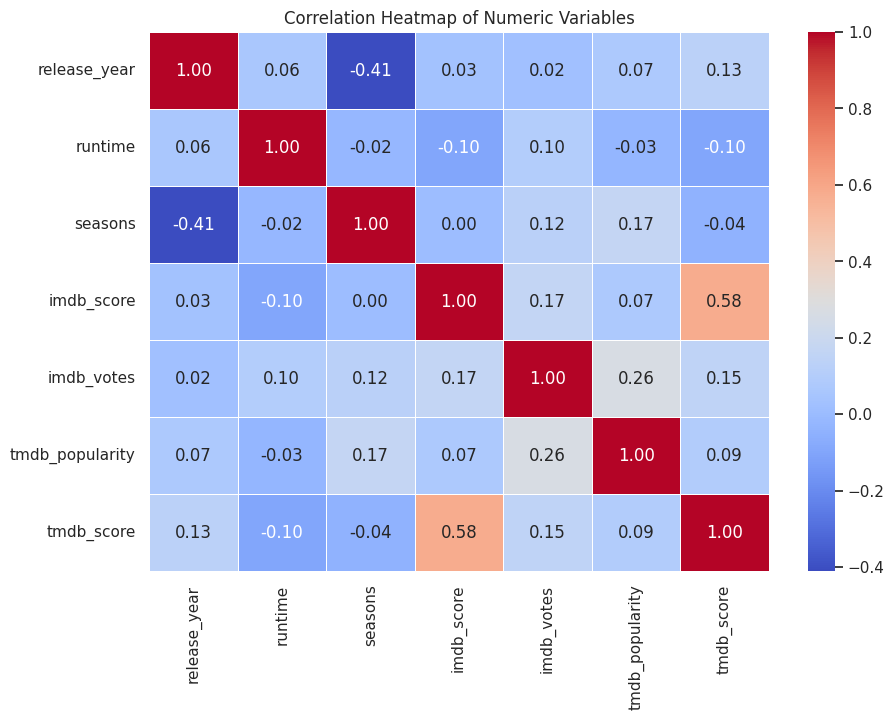

In [ ]:
# Chart - 10 visualization code
correlation_columns = [
    "release_year", "runtime", "seasons",
    "imdb_score", "imdb_votes",
    "tmdb_popularity", "tmdb_score"
]

corr = df[correlation_columns].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Numeric Variables")
plt.show()


##### 1. Why did you pick the specific chart?

A correlation heatmap summarizes the strength and direction of relationships between multiple numerical variables in one visual.

##### 2. What is/are the insight(s) found from the chart?

The heatmap identifies variables that move together and variables that have weak relationships. Ratings, popularity, vote counts and runtime can therefore be compared systematically.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

Correlation can help prioritize variables for deeper analysis. However, correlation does not prove causation, so business decisions should combine these results with domain context.

#### Chart - 11 - Pair Plot

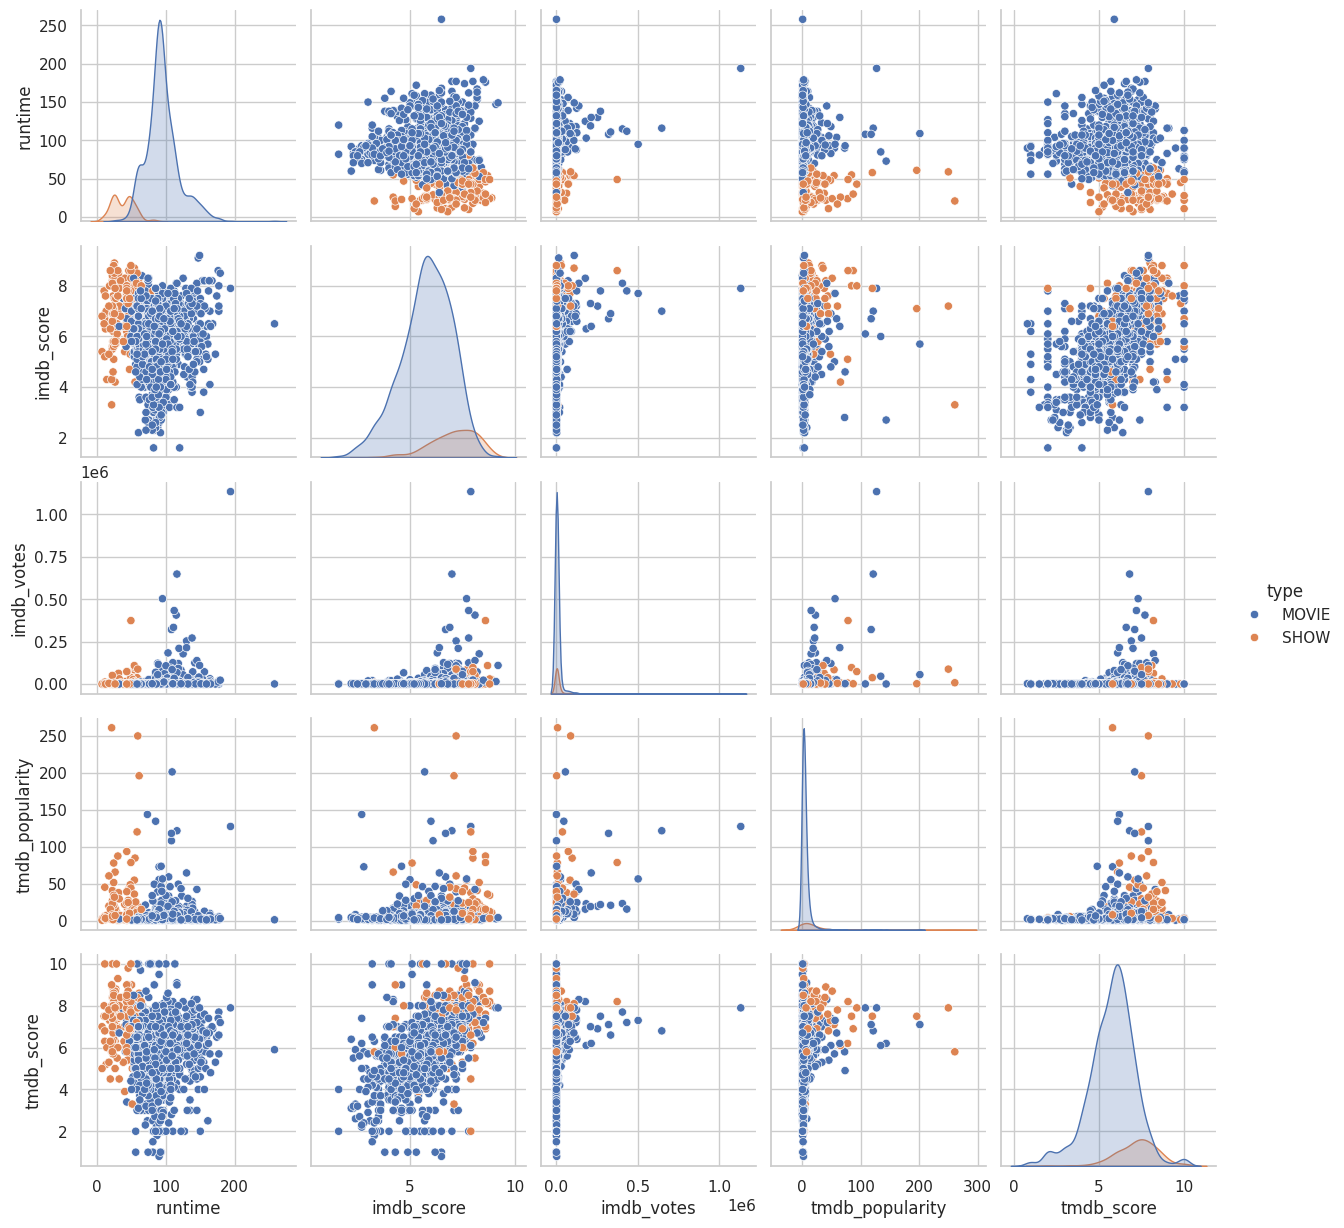

In [ ]:
# Pair Plot visualization code
pair_columns = [
    "runtime", "imdb_score", "imdb_votes",
    "tmdb_popularity", "tmdb_score"
]

pair_data = df[pair_columns + ["type"]].dropna()

# Limit the number of rows for faster Colab rendering
pair_sample = pair_data.sample(min(1500, len(pair_data)), random_state=42)

sns.pairplot(pair_sample, hue="type")
plt.show()


##### 1. Why did you pick the specific chart?

A pair plot provides multiple scatter plots and distributions at once, helping identify relationships, clusters and potential nonlinear patterns among numerical variables.

##### 2. What is/are the insight(s) found from the chart?

The pair plot gives a broader view of relationships between runtime, ratings, votes and popularity and allows movie and TV-show patterns to be compared.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

This visualization is useful for exploratory feature selection and hypothesis generation. The observed patterns should be validated with additional statistical analysis before strategic decisions are made.

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ? Explain Briefly.

**Solution for Amazon Prime Video Content Strategy**

* **Balance content formats:** Monitor the movie and TV-show mix and invest where audience demand and strategic gaps are identified.
* **Strengthen genre strategy:** Use genre volume together with ratings and popularity to identify strong categories and diversification opportunities.
* **Expand regional content intelligently:** Production-country analysis can guide regional acquisition and original-content strategies.
* **Monitor content trends:** Track yearly releases to understand whether the catalog is expanding, contracting or shifting toward newer content.
* **Combine quality and popularity:** IMDb score, IMDb votes and TMDB popularity should be evaluated together rather than relying on a single metric.
* **Use audience certification data:** Age certification can support programming decisions for different audience segments.
* **Leverage contributor analysis:** Actors and directors associated with many highly rated titles can be considered when evaluating future content opportunities.

# **Conclusion**

• Amazon Prime's catalog contains both movies and TV shows, allowing analysis of content-format strategy.
• Genre analysis reveals which categories dominate the platform's content library.
• Production-country analysis provides insight into geographic diversity and potential regional expansion.
• Release-year trends show how the catalog has evolved over time.
• IMDb ratings provide a useful quality indicator, while IMDb votes and TMDB popularity provide complementary signals of visibility and audience interest.
• Credits analysis identifies actors and directors with substantial participation across titles.
• Correlation and pair-plot analysis help identify relationships between ratings, votes, popularity and runtime.
• These insights can support content acquisition, production planning, regional strategy and audience segmentation, while avoiding decisions based on a single metric.

### ***Hurrah! You have successfully completed your Amazon Prime Video EDA Capstone Project !!!***

## **Final Dataset Validation**

In [ ]:
# Final validation checks
print("Final titles dataset shape:", df.shape)
print("Final credits dataset shape:", df_credits.shape)

print("\nMissing values in key analytical columns:")
key_columns = ["title", "type", "release_year", "runtime", "imdb_score", "imdb_votes", "tmdb_popularity", "tmdb_score"]
display(df[key_columns].isnull().sum().to_frame("Missing Values"))

print("\nContent type distribution:")
display(df["type"].value_counts().to_frame("Title Count"))

print("\nTop 10 genres:")
display(genre_counts.head(10))

print("\nTop 10 production countries:")
display(country_counts.head(10))


Final titles dataset shape: (9868, 18)
Final credits dataset shape: (124235, 5)

Missing values in key analytical columns:


,Missing Values
title,0
type,0
release_year,0
runtime,0
imdb_score,1021
imdb_votes,1031
tmdb_popularity,547
tmdb_score,2080



Content type distribution:


,Title Count
type,
MOVIE,8511
SHOW,1357



Top 10 genres:


,genres,title_count
0,drama,4762
1,comedy,2987
2,thriller,2119
3,action,1820
4,romance,1751
5,crime,1250
6,documentation,1096
7,horror,1065
8,family,751
9,european,712



Top 10 production countries:


,production_countries,title_count
0,US,5331
1,IN,1072
2,GB,928
3,CA,530
4,FR,250
5,JP,197
6,AU,173
7,DE,172
8,IT,143
9,CN,143
